## Feature Engineering

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('Dataset for Data Analytics.csv')

In [4]:
df_data = df.copy()

In [5]:
df_data.head(5)

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200853,2023-10-16,C10002,Printer,3,490.01,894 Main St,Cash,Returned,TRK94641152,4,SAVE10,Facebook,1470.03
1,ORD200037,2024-10-14,C10054,Laptop,2,76.74,409 Main St,Cash,Returned,TRK94005261,7,SAVE10,Instagram,153.48
2,ORD200201,2023-06-18,C10126,Monitor,2,674.90,146 Main St,Online,Shipped,TRK75607531,4,SAVE10,Facebook,1349.80
3,ORD200728,2024-07-29,C10154,Desk,4,325.76,827 Main St,Gift Card,Shipped,TRK79793300,8,WINTER15,Email,1303.04
4,ORD200991,2024-05-09,C10211,Desk,5,127.18,598 Main St,Debit Card,Cancelled,TRK68938335,10,FREESHIP,Google,635.90


In [6]:
df_data['TotalPrice'].sort_values(ascending = False)

654     3456.40
407     3390.95
787     3390.80
56      3384.90
124     3370.20
         ...   
1038      18.20
555       17.98
77        17.24
1173      14.06
318       11.39
Name: TotalPrice, Length: 1200, dtype: float64

In [7]:
df_data.describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


In [8]:
df_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   object 
 1   Date             1200 non-null   object 
 2   CustomerID       1200 non-null   object 
 3   Product          1200 non-null   object 
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   object 
 7   PaymentMethod    1200 non-null   object 
 8   OrderStatus      1200 non-null   object 
 9   TrackingNumber   1200 non-null   object 
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       1200 non-null   object 
 12  ReferralSource   1200 non-null   object 
 13  TotalPrice       1200 non-null   float64
dtypes: float64(2), int64(2), object(10)
memory usage: 131.4+ KB


In [9]:
# Change the data type of Date
df_data['Date'] = pd.to_datetime(df_data['Date']) 

In [10]:
df_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          1200 non-null   object        
 1   Date             1200 non-null   datetime64[ns]
 2   CustomerID       1200 non-null   object        
 3   Product          1200 non-null   object        
 4   Quantity         1200 non-null   int64         
 5   UnitPrice        1200 non-null   float64       
 6   ShippingAddress  1200 non-null   object        
 7   PaymentMethod    1200 non-null   object        
 8   OrderStatus      1200 non-null   object        
 9   TrackingNumber   1200 non-null   object        
 10  ItemsInCart      1200 non-null   int64         
 11  CouponCode       1200 non-null   object        
 12  ReferralSource   1200 non-null   object        
 13  TotalPrice       1200 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(

In [11]:
# Make Segment for TotalPrice
df_data.describe()
                      

,Date,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200,1200.000000,1200.000000,1200.000000,1200.000000
mean,2024-03-22 16:58:48,2.945833,356.412750,5.485000,1053.968300
min,2023-01-01 00:00:00,1.000000,11.390000,1.000000,11.390000
25%,2023-08-03 18:00:00,2.000000,186.062500,4.000000,410.520000
50%,2024-03-23 00:00:00,3.000000,364.210000,5.000000,823.615000
75%,2024-11-08 12:00:00,4.000000,521.570000,7.000000,1578.475000
max,2025-06-30 00:00:00,5.000000,699.930000,10.000000,3456.400000
std,NaN,1.407557,197.177146,2.281983,819.856558


In [12]:
def price_segment(price) :
    if price <= 500:
        return 'Low'
    elif price <= 1500:
        return 'Medium'
    else:
        return 'High'
df_data['PriceSegment'] = df_data['TotalPrice'].apply(price_segment)

In [13]:
def quantity_segment(quantity):
    if quantity <=2 :
        return 'Low'
    elif quantity <= 4 : 
        return 'Medium'
    else: 
        return 'High'
df_data['QuantitySegment'] = df_data['Quantity'].apply(quantity_segment)

In [14]:
df_data['Year'] = df_data['Date'].dt.year

In [15]:
df_data.head(5)

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,PriceSegment,QuantitySegment,Year
0,ORD200853,2023-10-16,C10002,Printer,3,490.01,894 Main St,Cash,Returned,TRK94641152,4,SAVE10,Facebook,1470.03,Medium,Medium,2023
1,ORD200037,2024-10-14,C10054,Laptop,2,76.74,409 Main St,Cash,Returned,TRK94005261,7,SAVE10,Instagram,153.48,Low,Low,2024
2,ORD200201,2023-06-18,C10126,Monitor,2,674.90,146 Main St,Online,Shipped,TRK75607531,4,SAVE10,Facebook,1349.80,Medium,Low,2023
3,ORD200728,2024-07-29,C10154,Desk,4,325.76,827 Main St,Gift Card,Shipped,TRK79793300,8,WINTER15,Email,1303.04,Medium,Medium,2024
4,ORD200991,2024-05-09,C10211,Desk,5,127.18,598 Main St,Debit Card,Cancelled,TRK68938335,10,FREESHIP,Google,635.90,Medium,High,2024


In [16]:
df_data['Year'] = pd.to_datetime(df_data['Year'])

In [17]:
df_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          1200 non-null   object        
 1   Date             1200 non-null   datetime64[ns]
 2   CustomerID       1200 non-null   object        
 3   Product          1200 non-null   object        
 4   Quantity         1200 non-null   int64         
 5   UnitPrice        1200 non-null   float64       
 6   ShippingAddress  1200 non-null   object        
 7   PaymentMethod    1200 non-null   object        
 8   OrderStatus      1200 non-null   object        
 9   TrackingNumber   1200 non-null   object        
 10  ItemsInCart      1200 non-null   int64         
 11  CouponCode       1200 non-null   object        
 12  ReferralSource   1200 non-null   object        
 13  TotalPrice       1200 non-null   float64       
 14  PriceSegment     1200 non-null   object 

## EDA

In [18]:
df_data.groupby(['OrderStatus','PriceSegment'])['TotalPrice'].sum().sort_values(ascending = False).unstack()

PriceSegment,High,Low,Medium
OrderStatus,,,
Cancelled,165254.47,19883.81,91257.93
Delivered,136049.26,20380.14,86170.92
Pending,151722.32,19787.01,84818.82
Returned,128435.32,20942.46,93899.92
Shipped,128431.36,20703.48,97024.74


In [19]:
df_data.groupby(['PriceSegment','OrderStatus'])['Quantity'].sum().sort_values(ascending = False).unstack()

OrderStatus,Cancelled,Delivered,Pending,Returned,Shipped
PriceSegment,,,,,
High,304,259,292,247,241
Low,174,156,169,163,161
Medium,281,275,263,272,278


In [20]:
df_data.groupby(['OrderStatus','PriceSegment'])['CustomerID'].count().sort_values(ascending = False).unstack()

PriceSegment,High,Low,Medium
OrderStatus,,,
Cancelled,74,79,97
Delivered,61,71,99
Pending,70,74,93
Returned,59,85,103
Shipped,58,74,103


In [29]:
df_data.groupby('PriceSegment')['TotalPrice'].mean().sort_values(ascending = False)

PriceSegment
High      2204.635807
Medium     915.499657
Low        265.527154
Name: TotalPrice, dtype: float64

In [30]:
df_data['PriceSegment'].mode()

0    Medium
Name: PriceSegment, dtype: object

## Visualization

<Axes: title={'center': 'Total Price by Price Segment and Order Status'}, xlabel='PriceSegment', ylabel='TotalPrice'>

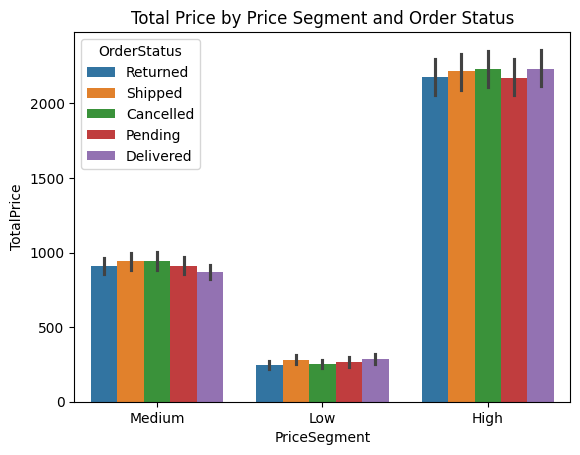

In [22]:
plt.title('Total Price by Price Segment and Order Status')
sns.barplot(x = 'PriceSegment', y = 'TotalPrice', data = df_data, hue = 'OrderStatus')

<Axes: xlabel='Year', ylabel='TotalPrice'>

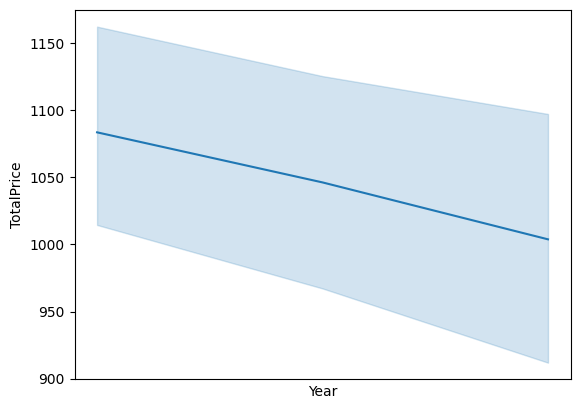

In [23]:
sns.lineplot(x = 'Year', y = 'TotalPrice', data = df_data)

<Axes: title={'center': 'Quantity by Quantity Segment'}, ylabel='Quantity'>

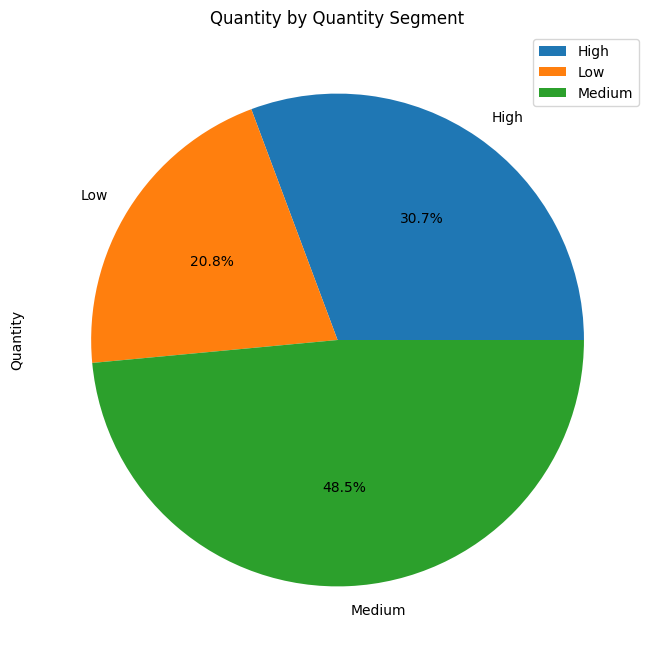

In [24]:
plt.title('Quantity by Quantity Segment')
df_data.groupby('QuantitySegment')['Quantity'].sum().plot(kind = 'pie', autopct = '%1.1f%%',legend = True, figsize = (8,8) )

<Axes: title={'center': 'Total Price by Year'}, xlabel='Year'>

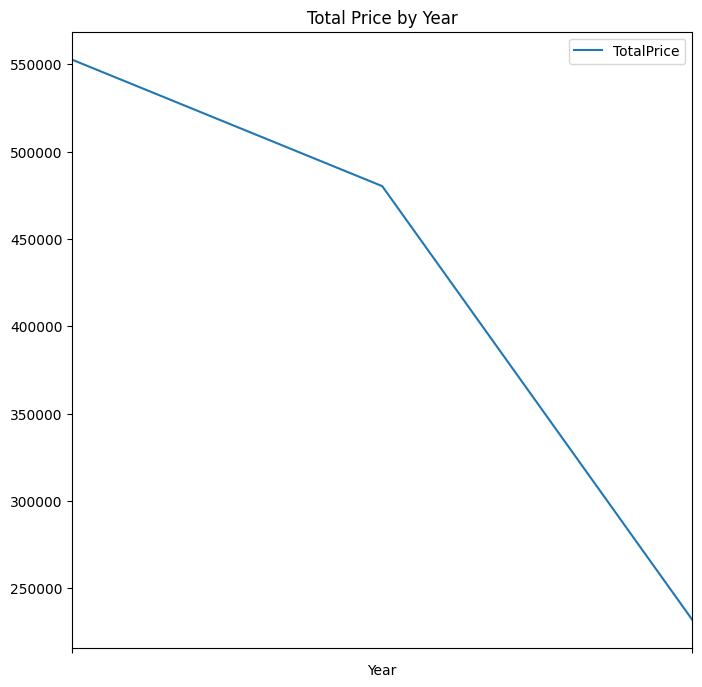

In [25]:
plt.title('Total Price by Year')
df_data.groupby('Year')['TotalPrice'].sum().plot(kind = 'line', legend = True, figsize = (8,8) )

<Axes: title={'center': 'Total Price by Price Segment'}, xlabel='PriceSegment'>

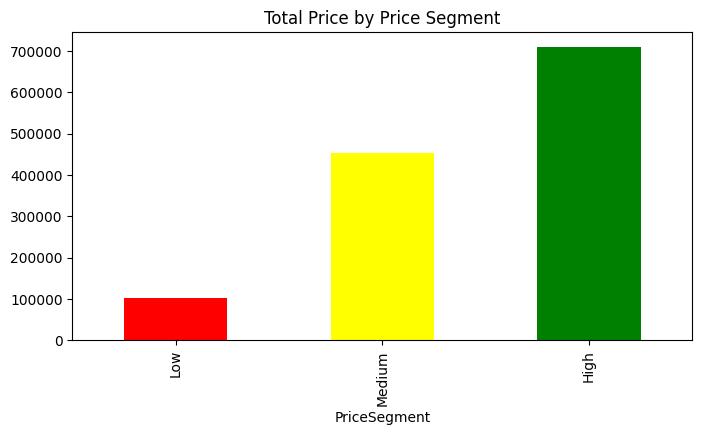

In [26]:
plt.title('Total Price by Price Segment')
df_data.groupby('PriceSegment')['TotalPrice'].sum().sort_values(ascending = True).plot(kind = 'bar',  figsize = (8,4),color = ['red','yellow','green'])

<Axes: >

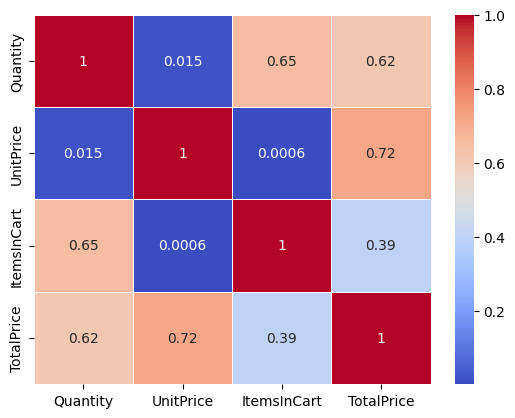

In [27]:
# Correlation between TotalPrice and Quantity
corr = df_data.corr(numeric_only = True)
sns.heatmap(corr, annot = True, cmap = 'coolwarm', linewidths = 0.5)
